## Exercise 2 HW: Introduction to PyTorch

As the first step, we need to install a suitable version of PyTorch.
Generally, it should work to simply add the `torch` package to the uv project you created in the previous week.
To have the tools to visualize results, we will also install `matplotlib`.
Open a terminal, move into the uv project directory of the previous week, then run:
```
uv add torch matplotlib
```

If you run into problems regarding the PyTorch version, go to https://pytorch.org/ and scroll down to the install section for instructions on how to install specific versions.

Alternatively, you can use [Google Colab](https://colab.research.google.com/).
This is a free service by Google that allows you to run Jupyter notebooks in their cloud.
You can get GPU access by changing the runtime type in the top bar (Runtime → Change runtime type), although a GPU is not needed for this exercise.
Their default environment has most standard packages installed, including PyTorch.

## Polynomial Regression

Polynomial regression is slightly more complex than linear regression.
Instead of modeling the outcome as a linear combination of the features, polynomial regression models it as a linear combination of powers of the features.
In the case of a single feature, i.e., inputs $x \in \mathbb{R}$, the model is defined as:
$$f(x,w) = w_0 + w_1 x + w_2 x^2 + w_3 x^3 + \dots + w_q x^q.$$

In the more general case, where $x \in \mathbb{R}^p$, a simple version of the model is defined as:
$$f(x,w) = w_0 + w_{11} x_1 + w_{12} x_1^2 + \dots + w_{1q} x_1^q + w_{21} x_2 + w_{22} x_2^2 + \dots + w_{2q} x_2^q + \dots = w_0 + \sum_{i=1}^p \sum_{j=1}^q w_{ij} x_i^j.$$
A full polynomial model of degree $q$ would additionally contain interaction terms such as $x_1 x_2$ or $x_1^2 x_3$; we omit them here.

Note that although $f$ is nonlinear in $x$, it is still *linear in the weights* $w$: polynomial regression is linear regression on the transformed features $(x, x^2, \dots, x^q)$.

In this task, you implement a one-dimensional polynomial regression model in PyTorch and study how the allowed complexity of the model (the degree $q$) affects the quality of the fit to data.

1. Import `torch` and `matplotlib.pyplot` as `plt`. The second library is commonly imported with this alias.

In [1]:
import matplotlib.pyplot as plt
import torch

The following cell creates synthetic data that your model will have to fit.
The ground-truth function is a polynomial of degree 3, and the targets are corrupted with Gaussian noise (standard deviation 0.4).
There are only 10 training points and 25 validation points; all tensors have shape `(n, 1)`.

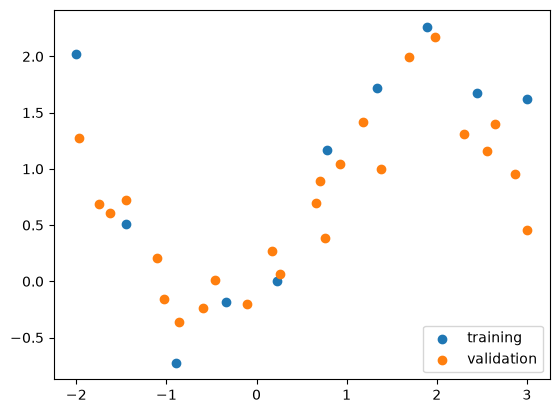

In [2]:
torch.manual_seed(1234)
torch.use_deterministic_algorithms(True)
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = False

n_points = 10


def make_targets(x):
    return x + 0.5 * x**2 - 0.25 * x**3 + 0.4 * torch.randn_like(x)


x = torch.linspace(-2, 3, n_points).reshape(-1, 1)
y = make_targets(x)

x_val = torch.linspace(-2, 3, 25).reshape(-1, 1) + 0.1 * torch.randn((25, 1))
y_val = make_targets(x_val)

plt.scatter(x, y, label="training")
plt.scatter(x_val, y_val, label="validation")
plt.legend()
plt.show()

2. Implement a one-dimensional polynomial regression model.
    1. Create a class `PolyRegression` that inherits from `torch.nn.Module`.
    2. Create the `__init__` method. The method should have an integer argument that specifies the degree of the polynomial that will be fitted. The weights can be created with a `torch.nn.Linear` layer, but you can also look at different approaches like using `torch.nn.parameter.Parameter`. Do not forget to call the `__init__` of the parent class first.
    3. Create the `forward` method. It receives inputs of shape `(N, 1)`, should return predictions of shape `(N, 1)`, and should implement the first equation of this notebook: $$f(x,w) = w_0 + w_1 x + w_2 x^2 + w_3 x^3 + \dots + w_q x^q.$$


Hint 1: `torch.pow` can be used to raise a tensor to a power.

Hint 2: The PyTorch documentation can help you if you are stuck.

In [3]:
class PolyRegression(torch.nn.Module):
    def __init__(self, poly_degree: int):
        super().__init__()

        self.max_degree = poly_degree
        # w_1, ..., w_q are the weights of the linear layer, w_0 is its bias
        self.linear = torch.nn.Linear(self.max_degree, 1, bias=True)

    def forward(self, x):
        # (N, 1) -> (N, q) with columns x, x^2, ..., x^q
        exponentiated_features = torch.concat(
            [torch.pow(x, exponent) for exponent in range(1, self.max_degree + 1)],
            dim=1,
        )
        return self.linear(exponentiated_features)


# Test that your model works
model = PolyRegression(3)
out = model(x)
assert out.shape == (n_points, 1), (
    f"Expected output shape {(n_points, 1)}, got {tuple(out.shape)}"
)

3. Complete the following function, which performs one training epoch. It should implement the five general training steps.

In [4]:
def train_one_epoch(x, y, model, optimizer, loss_func):
    """Optimizes the parameters of model with one pass over the training data.

    Args:
        x (torch.Tensor): inputs
        y (torch.Tensor): targets
        model (torch.nn.Module): model to train
        optimizer (torch.optim.Optimizer): optimizer holding the model's parameters
        loss_func (callable): loss function, called as loss_func(prediction, target)

    Returns:
        float: training loss of this epoch
    """
    output = model(x)  # Step 1: forward pass
    loss = loss_func(output, y)  # Step 2: compute loss
    optimizer.zero_grad()  # Step 3: zero all .grad attributes
    loss.backward()  # Step 4: compute gradients (populate .grad attributes)
    optimizer.step()  # Step 5: update parameters based on gradients
    return loss.item()

4. Complete the following function, which computes the loss on validation data. Use the `torch.no_grad` function decorator or the `torch.no_grad` context manager inside this function to avoid making computations relevant for the gradient computation.

We call the function `evaluate` rather than `eval`, since `eval` is a built-in Python function that we do not want to shadow.

In [5]:
@torch.no_grad()
def evaluate(x, y, model, loss_func):
    """Computes the loss over validation data.

    Args:
        x (torch.Tensor): inputs
        y (torch.Tensor): targets
        model (torch.nn.Module): model to evaluate
        loss_func (callable): loss function, called as loss_func(prediction, target)

    Returns:
        float: validation loss
    """
    # Our model behaves identically in training and evaluation. Models with layers such
    # as dropout or batch normalization additionally need model.eval() here (and
    # model.train() before training), because these layers behave differently in both modes.
    output = model(x)
    loss = loss_func(output, y)
    return loss.item()

5. Combine the above functions to train a polynomial regression model of degree 3. The cell should instantiate a model, an optimizer, and a loss function suitable for regression, then iterate `n_epochs` times over the data to optimize the model. To ease optimization, use the `torch.optim.Adam` optimizer with `lr=5e-3`. To see whether you are overfitting, check the validation loss on `x_val, y_val` from time to time, e.g., every 500 epochs.

In [6]:
torch.manual_seed(123)  # fixes initialization of parameters

model = PolyRegression(3)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-3)
loss_func = torch.nn.MSELoss()

n_epochs = 5_000
print_every_n_epochs = 500
for epoch in range(n_epochs + 1):
    train_loss = train_one_epoch(x, y, model, optimizer, loss_func)

    if epoch % print_every_n_epochs == 0:
        val_loss = evaluate(x_val, y_val, model, loss_func)
        print(f"epoch {epoch:5d}: train_loss={train_loss:.4f}  val_loss={val_loss:.4f}")

epoch     0: train_loss=16.1716  val_loss=11.6471
epoch   500: train_loss=0.2474  val_loss=0.2477
epoch  1000: train_loss=0.0860  val_loss=0.1850
epoch  1500: train_loss=0.0580  val_loss=0.1995
epoch  2000: train_loss=0.0562  val_loss=0.2089
epoch  2500: train_loss=0.0562  val_loss=0.2105
epoch  3000: train_loss=0.0562  val_loss=0.2107
epoch  3500: train_loss=0.0562  val_loss=0.2107
epoch  4000: train_loss=0.0562  val_loss=0.2107
epoch  4500: train_loss=0.0562  val_loss=0.2107
epoch  5000: train_loss=0.0562  val_loss=0.2107


6. Name three hyperparameters you use in your code.

*Solution*: The learning rate, the degree of the polynomial, and the number of epochs. Other valid answers include the choice of optimizer and its further settings (e.g., Adam's $\beta$ parameters) and the choice of loss function.

7. Visualize the resulting model with the following cell. It defines a helper function `plot_model` that you can reuse in the next task.

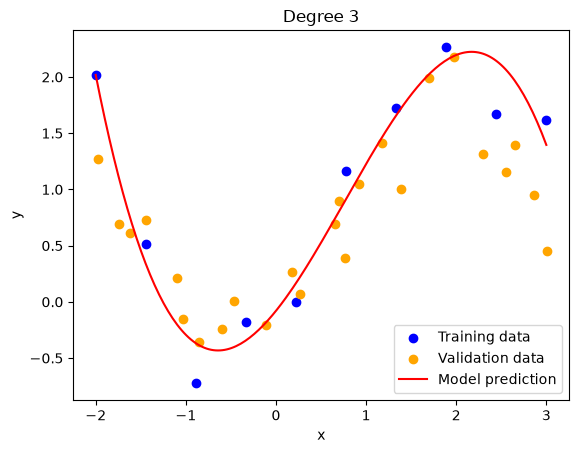

In [7]:
def plot_model(model, title=None):
    _fig, ax = plt.subplots()
    ax.scatter(x.view(-1), y.view(-1), color="blue", label="Training data")
    ax.scatter(x_val.view(-1), y_val.view(-1), color="orange", label="Validation data")

    with torch.no_grad():
        x_plot = torch.linspace(x.min().item(), x.max().item(), 200).view(-1, 1)
        pred_plot = model(x_plot)
    ax.plot(x_plot, pred_plot, label="Model prediction", color="red")

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    if title is not None:
        ax.set_title(title)
    ax.legend()
    plt.show()


plot_model(model, title="Degree 3")

8. Revisit the model training.
    1. Train a model with a much higher degree of the polynomial, e.g., degree 9. You may need to change the number of epochs and the learning rate of the optimizer. How does the fit compare to the fit of the model with degree 3? Compare the final training *and* validation losses, not just the plots.
    2. What happens if you train a model with degree 1 or 2? Are you over- or underfitting; why?

Hint 1: Call `torch.manual_seed(123)` before creating each model so that your runs are reproducible.

Hint 2: $x$ takes values up to 3, so the feature $x^q$ quickly becomes large ($3^9 \approx 20\,000$). This makes gradient-based optimization of high-degree models slow and sensitive to the learning rate.

Hint 3: Every degree-3 polynomial is also a polynomial of higher degree (with the extra weights set to zero). After convergence, a higher-degree model must therefore reach a training loss at most as large as the degree-3 model. If your training loss is higher, the optimization has not converged yet.

epoch     0: train_loss=4092747.2500  val_loss=2522783.0000
epoch  2000: train_loss=24.5324  val_loss=25.4529
epoch  4000: train_loss=0.9511  val_loss=1.6830
epoch  6000: train_loss=0.5690  val_loss=1.3412
epoch  8000: train_loss=0.2472  val_loss=1.1038
epoch 10000: train_loss=0.0984  val_loss=0.9001
epoch 12000: train_loss=14.6930  val_loss=14.7482
epoch 14000: train_loss=0.0571  val_loss=0.6758
epoch 16000: train_loss=0.0527  val_loss=0.6506
epoch 18000: train_loss=0.0492  val_loss=0.6348
epoch 20000: train_loss=0.0461  val_loss=0.6222


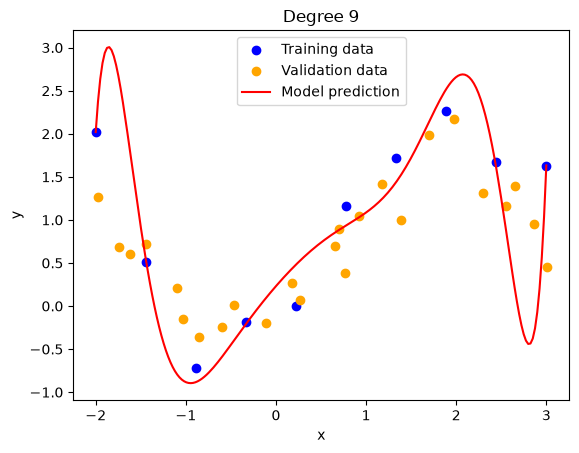

In [8]:
# 8.1: Higher-degree polynomial (degree 9)

torch.manual_seed(123)  # fixes initialization of parameters

model_high = PolyRegression(9)
optimizer = torch.optim.Adam(model_high.parameters(), lr=5e-3)
loss_func = torch.nn.MSELoss()

n_epochs = 20_000
print_every_n_epochs = 2_000
for epoch in range(n_epochs + 1):
    train_loss = train_one_epoch(x, y, model_high, optimizer, loss_func)

    if epoch % print_every_n_epochs == 0:
        val_loss = evaluate(x_val, y_val, model_high, loss_func)
        print(f"epoch {epoch:5d}: train_loss={train_loss:.4f}  val_loss={val_loss:.4f}")

plot_model(model_high, title="Degree 9")

*Solution 8.1*: With 10 training points, a degree-9 polynomial has enough parameters (10) to pass through every training point exactly. After 20,000 epochs, its training loss (≈0.046) is lower than that of the degree-3 model (≈0.056), but its validation loss (≈0.62) is about three times as high (≈0.21). The plot shows why: the curve oscillates strongly between the training points, especially near the edges of the interval, so it fits the noise in the training data rather than the underlying function. The model is overfitting.

Notes on the optimization:
- The degree-3 model is a special case of the degree-9 model, so at convergence the training loss of the degree-9 model must be at most ≈0.056. With too few epochs or an unsuitable learning rate, the training loss stays above that value, and the resulting curve says little about overfitting.
- Convergence is slow because the features $x, x^2, \dots, x^9$ live on very different scales. For even higher degrees (e.g., 12), Adam does not reach a good fit within a reasonable number of epochs. Rescaling the inputs would help.
- For moderately higher degrees, the effect is much weaker on this data. A degree-6 model, trained to convergence (≈50,000 epochs with `lr=5e-4`), reaches a validation loss of ≈0.21, about the same as the degree-3 model.

degree 1: train_loss=0.7522  val_loss=0.4228


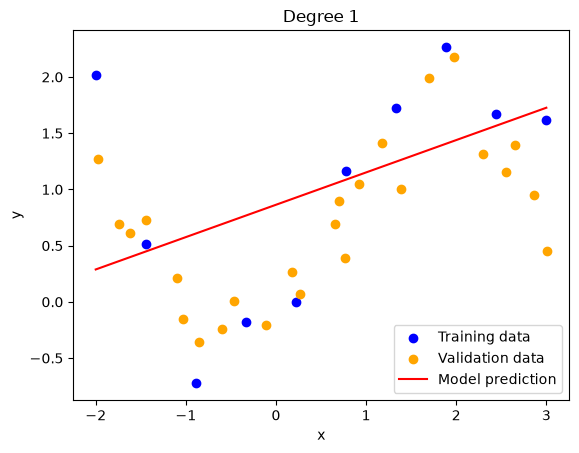

degree 2: train_loss=0.5727  val_loss=0.4553


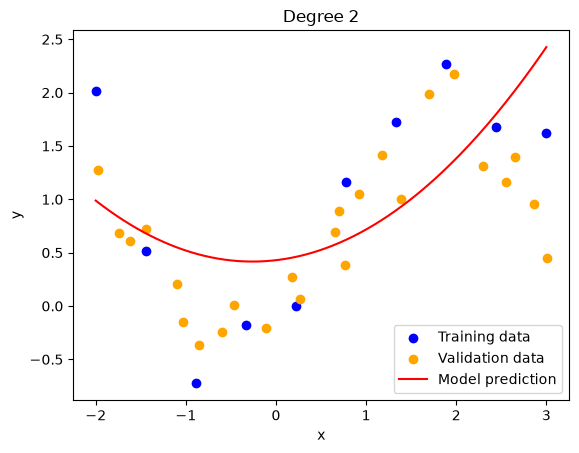

In [9]:
# 8.2: Low-degree polynomials (degree 1 and 2)

loss_func = torch.nn.MSELoss()
for degree in [1, 2]:
    torch.manual_seed(123)  # fixes initialization of parameters
    model_low = PolyRegression(degree)
    optimizer = torch.optim.Adam(model_low.parameters(), lr=5e-3)

    for epoch in range(5_000):
        train_loss = train_one_epoch(x, y, model_low, optimizer, loss_func)

    val_loss = evaluate(x_val, y_val, model_low, loss_func)
    print(f"degree {degree}: train_loss={train_loss:.4f}  val_loss={val_loss:.4f}")
    plot_model(model_low, title=f"Degree {degree}")

*Solution 8.2*: Both models underfit. The data was generated by a degree-3 polynomial with two turning points, a shape that a line or a parabola cannot represent. Accordingly, both the training loss (≈0.75 for degree 1, ≈0.57 for degree 2) and the validation loss (≈0.42 and ≈0.46) are far higher than for the degree-3 model (≈0.06 and ≈0.21). The hallmark of underfitting is that the model performs poorly even on the training data, whereas an overfitting model has a low training loss but a high validation loss.

9. How would you classify this task in the scheme of slide 6 in deck 2?

*Solution*: It is a supervised learning problem, since we learn from labeled input–target pairs. More specifically, it is a regression problem, since the targets are continuous real values.